# Validating impute_sex() on public human and mouse data

Notebook version of `vignettes/impute-sex.Rmd`.

In [3]:
# Run this notebook from vignettes/ (or the package root) with the "R" (ir) kernel.
setwd("/camp/home/hungm/working/Matthew/git-repos/r-dev/BiowrenchR")
pkg_root <- normalizePath(if (file.exists("DESCRIPTION")) "." else "..")

# Use the project's renv library (copied from the seurat5 env).
# Set to FALSE to use whatever library the kernel already has.
use_renv <- TRUE
if (use_renv) {
  Sys.setenv(RENV_PATHS_LIBRARY = file.path(pkg_root, "renv", "library"))
  renv::load(pkg_root)
}

# Load biowrenchR from source (no install needed)
pkgload::load_all(pkg_root, quiet = TRUE)

# Notebook equivalent of knitr::kable(): return a data frame for rich display
show_table <- function(x, row.names = FALSE, digits = NULL) {
  if (!is.null(digits)) {
    num <- vapply(x, is.numeric, logical(1))
    x[num] <- lapply(x[num], round, digits)
  }
  if (!row.names) rownames(x) <- NULL
  x
}

options(repr.plot.width = 12, repr.plot.height = 8, repr.plot.res = 110,
        repr.matrix.max.rows = 50)

`impute_sex()` assigns each sample to `"female"` or `"male"` by k-means
clustering (k = 2) on sex-chromosome marker genes:

* **female markers**: X-inactivation escape genes (`XIST`, `RPS4X`, ... /
  `Xist`, `Kdm6a`, ...);
* **male markers**: all Y-chromosome genes in the packaged BioMart dictionary.

The cluster with higher female-marker and lower male-marker expression is
called female.

This vignette checks the calls against the recorded sex of samples in eight
public GEO datasets, covering both organisms, microarray and RNA-seq, and
a range of tissues. GEO sex labels are themselves sometimes wrong, so every
call is also compared with a simple independent read-out: a score built from
a handful of strongly expressed Y genes.

In [4]:
set.seed(2026)

datasets <- readRDS(system.file("extdata", "impute_sex_validation.rds",
                                package = "biowrenchR"))

## Data

The bundled file holds, for each dataset, a log-scale expression matrix
(log2 intensities for arrays, log2(CPM + 1) for RNA-seq) restricted to
sex-marker genes, plus the sex recorded in GEO. It is built by
`data-raw/impute_sex_validation.R` in the package source, which downloads the
series matrices / count tables from GEO, maps probes to gene symbols and
normalises.

In [5]:
overview <- do.call(rbind, lapply(datasets, function(d) data.frame(
  Dataset = d$id, Organism = d$org, Platform = d$platform, Tissue = d$tissue,
  Samples = ncol(d$exprs), Female = sum(d$sex == "female"),
  Male = sum(d$sex == "male"), `Marker genes` = nrow(d$exprs),
  check.names = FALSE
)))
show_table(overview, row.names = FALSE)

Dataset,Organism,Platform,Tissue,Samples,Female,Male,Marker genes
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>
GSE19151,human,Affymetrix HG-U133A 2.0,Whole blood,133,72,61,37
GSE15222,human,Illumina HumanRef-8,Brain cortex,363,173,190,50
GSE107011,human,RNA-seq,PBMC + sorted immune cell subsets,127,61,66,129
GSE60424,human,RNA-seq,Blood cell subsets,113,100,13,129
GSE4324,mouse,Affymetrix MOE430A,Spleen white blood cells,48,24,24,15
GSE240873,mouse,Agilent 4x44K,Hippocampus,31,16,15,18
GSE266332,mouse,RNA-seq,Eye,64,33,31,69
GSE199722,mouse,RNA-seq,Hippocampus,55,43,12,1560


`GSE107011` (Monaco et al.) contains PBMC and
many sorted immune cell subsets: a stress
test, since cell-type differences could dominate the clustering. `GSE4324`
contains intact and gonadectomised mice, so calls should follow sex
chromosomes, not hormones. `GSE60424` and `GSE199722` are strongly
unbalanced.

## Independent check: core Y-gene score

For each dataset, the mean z-score of a few well-expressed Y genes is split
into two groups by one-dimensional k-means. Where the GEO label and this
Y-score call disagree, the label is the more likely error.

In [6]:
core_genes <- list(
  human = list(
    y = c("RPS4Y1", "DDX3Y", "KDM5D", "UTY", "EIF1AY", "USP9Y", "ZFY", "NLGN4Y"),
    x = c("XIST", "RPS4X", "KDM5C", "KDM6A", "ZFX", "DDX3X")
  ),
  mouse = list(
    y = c("Ddx3y", "Kdm5d", "Uty", "Eif2s3y"),
    x = c("Xist", "Kdm6a", "Kdm5c", "Eif2s3x", "Ddx3x")
  )
)

gene_score <- function(exprs, genes) {
  genes <- intersect(genes, rownames(exprs))
  m <- exprs[genes, , drop = FALSE]
  m <- m[apply(m, 1, stats::var) > 0, , drop = FALSE]
  rowMeans(scale(t(m)))
}

y_score_call <- function(y) {
  km <- stats::kmeans(y, 2, nstart = 25)
  ifelse(km$cluster == which.max(km$centers), "male", "female")
}

run_dataset <- function(d) {
  cg <- core_genes[[d$org]]
  y <- gene_score(d$exprs, cg$y)
  data.frame(
    dataset = d$id, org = d$org, sample = colnames(d$exprs),
    label = unname(d$sex),
    group = if (is.null(d$group)) NA_character_ else unname(d$group),
    pred = unname(impute_sex(d$exprs, org = d$org)),
    pred_scaled = unname(impute_sex(d$exprs, org = d$org, scale = TRUE)),
    y_score = y, x_score = gene_score(d$exprs, cg$x),
    y_call = y_score_call(y)
  )
}

calls <- do.call(rbind, lapply(datasets, run_dataset))

## Accuracy

In [7]:
acc <- function(a, b) sprintf("%d/%d (%.1f%%)", sum(a == b), length(a), 100 * mean(a == b))
summary_tab <- do.call(rbind, lapply(split(calls, calls$dataset), function(x) data.frame(
  Dataset = x$dataset[1], Organism = x$org[1],
  `vs GEO label` = acc(x$pred, x$label),
  `vs Y-score call` = acc(x$pred, x$y_call),
  `GEO label vs Y-score` = acc(x$label, x$y_call),
  `scale = TRUE vs Y-score` = acc(x$pred_scaled, x$y_call),
  check.names = FALSE
)))
summary_tab <- summary_tab[match(names(datasets), summary_tab$Dataset), ]
show_table(summary_tab, row.names = FALSE)

Dataset,Organism,vs GEO label,vs Y-score call,GEO label vs Y-score,scale = TRUE vs Y-score
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
GSE19151,human,130/133 (97.7%),133/133 (100.0%),130/133 (97.7%),133/133 (100.0%)
GSE15222,human,337/363 (92.8%),352/363 (97.0%),346/363 (95.3%),358/363 (98.6%)
GSE107011,human,127/127 (100.0%),127/127 (100.0%),127/127 (100.0%),127/127 (100.0%)
GSE60424,human,113/113 (100.0%),113/113 (100.0%),113/113 (100.0%),113/113 (100.0%)
GSE4324,mouse,47/48 (97.9%),48/48 (100.0%),47/48 (97.9%),47/48 (97.9%)
GSE240873,mouse,31/31 (100.0%),31/31 (100.0%),31/31 (100.0%),31/31 (100.0%)
GSE266332,mouse,62/64 (96.9%),64/64 (100.0%),62/64 (96.9%),64/64 (100.0%)
GSE199722,mouse,55/55 (100.0%),55/55 (100.0%),55/55 (100.0%),55/55 (100.0%)


In [8]:
cat(sprintf(
  "Across all %d samples, impute_sex() agrees with the GEO label for %d\nand with the independent Y-score call for %d.\n",
  nrow(calls), sum(calls$pred == calls$label), sum(calls$pred == calls$y_call)))

Across all 934 samples, impute_sex() agrees with the GEO label for 902
and with the independent Y-score call for 923.


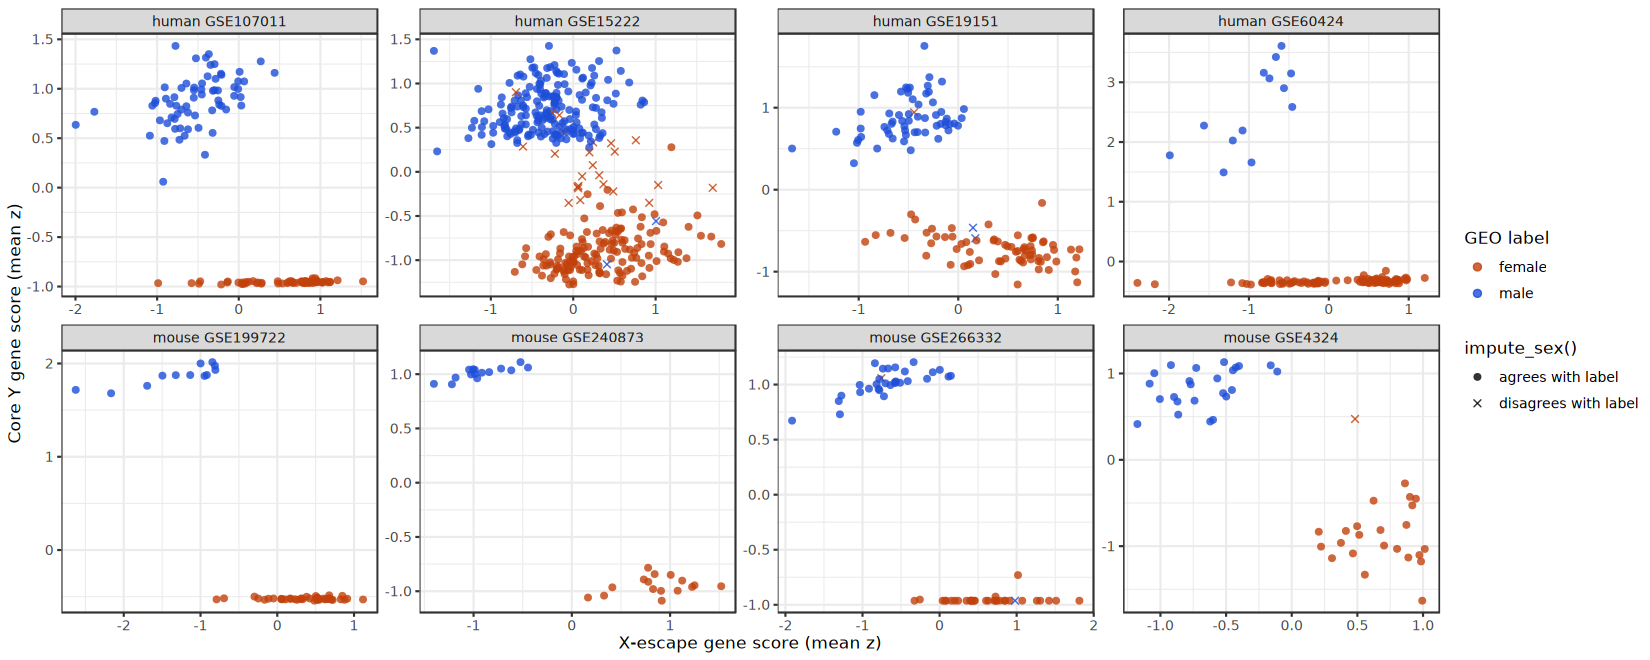

In [19]:
options(repr.plot.height = 6, repr.plot.width = 15)
library(ggplot2)
calls$agreement <- ifelse(calls$pred == calls$label,
                          "agrees with label", "disagrees with label")
ggplot(calls, aes(x_score, y_score, colour = label, shape = agreement)) +
  geom_point(size = 1.8, alpha = 0.8) +
  scale_shape_manual(values = c(16, 4)) +
  scale_colour_manual(values = c(female = "#c2410c", male = "#1d4ed8")) +
  facet_wrap(~ paste(org, dataset), scales = "free", ncol = 4) +
  labs(x = "X-escape gene score (mean z)", y = "Core Y gene score (mean z)",
       colour = "GEO label", shape = "impute_sex()") +
  theme_bw()

Samples whose label disagrees with the imputed sex (crosses) usually sit
squarely inside the *other* sex's cluster. That pattern points to a wrong
label rather than a wrong call.

## Discordant samples

In [10]:
show_genes <- list(human = c("XIST", "RPS4Y1", "DDX3Y", "KDM5D"),
                   mouse = c("Xist", "Ddx3y", "Kdm5d", "Uty"))
discordant <- calls[calls$pred != calls$label, ]
discordant$markers <- vapply(seq_len(nrow(discordant)), function(i) {
  d <- datasets[[discordant$dataset[i]]]
  g <- intersect(show_genes[[d$org]], rownames(d$exprs))
  paste(sprintf("%s=%.1f", g, d$exprs[g, discordant$sample[i]]), collapse = " ")
}, character(1))
show_table(
  discordant[c("dataset", "sample", "label", "pred", "y_call", "y_score", "markers")],
  row.names = FALSE, digits = 2
)

dataset,sample,label,pred,y_call,y_score,markers
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
GSE19151,GSM474724,female,male,male,0.94,XIST=4.4 RPS4Y1=11.7 DDX3Y=8.8 KDM5D=10.0
GSE19151,GSM474725,male,female,female,-0.59,XIST=9.3 RPS4Y1=6.5 DDX3Y=4.6 KDM5D=5.2
GSE19151,GSM474830,male,female,female,-0.46,XIST=8.7 RPS4Y1=7.2 DDX3Y=4.3 KDM5D=5.3
GSE15222,GSM225679,female,male,male,-0.05,RPS4Y1=8.4 DDX3Y=0.0 KDM5D=5.4
GSE15222,GSM225732,female,male,male,0.20,RPS4Y1=8.3 DDX3Y=4.5 KDM5D=4.8
GSE15222,GSM225736,female,male,male,0.29,RPS4Y1=9.6 DDX3Y=0.0 KDM5D=7.0
GSE15222,GSM225933,female,male,female,-0.15,RPS4Y1=8.3 DDX3Y=3.5 KDM5D=3.1
GSE15222,GSM225936,female,male,female,-0.16,RPS4Y1=8.4 DDX3Y=6.1 KDM5D=5.1
GSE15222,GSM225939,female,male,male,0.46,RPS4Y1=8.8 DDX3Y=3.4 KDM5D=5.9


For reference, the median marker expression per labelled sex:

In [11]:
medians <- do.call(rbind, lapply(datasets, function(d) {
  g <- intersect(show_genes[[d$org]], rownames(d$exprs))
  do.call(rbind, lapply(c("female", "male"), function(s) {
    med <- apply(d$exprs[g, d$sex == s, drop = FALSE], 1, stats::median)
    data.frame(dataset = d$id, label = s,
               markers = paste(sprintf("%s=%.1f", g, med), collapse = " "))
  }))
}))
show_table(medians, row.names = FALSE)

dataset,label,markers
<chr>,<chr>,<chr>
GSE19151,female,XIST=10.0 RPS4Y1=7.2 DDX3Y=4.4 KDM5D=5.2
GSE19151,male,XIST=4.5 RPS4Y1=12.5 DDX3Y=8.5 KDM5D=9.5
GSE15222,female,RPS4Y1=0.0 DDX3Y=0.0 KDM5D=1.4
GSE15222,male,RPS4Y1=10.2 DDX3Y=2.8 KDM5D=8.1
GSE107011,female,XIST=9.1 RPS4Y1=0.0 DDX3Y=0.2 KDM5D=0.1
GSE107011,male,XIST=0.2 RPS4Y1=6.0 DDX3Y=8.6 KDM5D=7.9
GSE60424,female,XIST=8.8 RPS4Y1=0.1 DDX3Y=0.2 KDM5D=0.0
GSE60424,male,XIST=0.3 RPS4Y1=7.7 DDX3Y=8.5 KDM5D=7.6
GSE4324,female,Xist=12.9 Ddx3y=2.9 Kdm5d=6.9 Uty=6.0


Most discordant samples have the marker profile of the opposite sex (for
example, labelled female with low *XIST* and high *RPS4Y1* / *KDM5D*).
Such samples are most likely mislabelled in GEO, a known and
common problem in public data. `GSE15222` (an older Illumina array without
an *XIST* probe) also has a group of samples with intermediate Y signal
that fall between the clusters; k-means must assign them to one side, so
treat calls in such data with care.

One mouse sample, `GSM98652` (`GSE4324`), expresses both *Xist* and Y genes at
high levels. That profile suggests a mixed or contaminated sample rather than
a simple label swap, and no two-way call is reliable for it.

## Gonadectomy does not affect calls (mouse, GSE4324)

In [12]:
g <- calls[calls$dataset == "GSE4324", ]
table(label = g$label, imputed = g$pred, treatment = g$group)

, , treatment = gonadectomised

        imputed
label    female male
  female     12    0
  male        0   12

, , treatment = intact

        imputed
label    female male
  female     11    1
  male        0   12


## Cell-type heterogeneity (human, GSE107011)

In [13]:
m <- calls[calls$dataset == "GSE107011", ]
cat(length(unique(m$group)), "cell types;",
    sum(m$pred == m$label), "/", nrow(m), "samples correct\n")

30 cell types; 127 / 127 samples correct


## Effect of `scale`

In [14]:
diff_scale <- calls[calls$pred != calls$pred_scaled, ]
show_table(
  diff_scale[c("dataset", "sample", "label", "pred", "pred_scaled", "y_call", "y_score")],
  row.names = FALSE, digits = 2
)

dataset,sample,label,pred,pred_scaled,y_call,y_score
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
GSE15222,GSM225933,female,male,female,female,-0.15
GSE15222,GSM226052,female,male,female,female,-0.35
GSE15222,GSM226147,female,male,female,female,-0.32
GSE15222,GSM226148,female,male,female,male,0.33
GSE15222,GSM388279,female,male,female,female,-0.14
GSE15222,GSM388333,female,male,female,female,-0.22
GSE15222,GSM388340,female,male,female,female,-0.18
GSE15222,GSM388354,female,male,female,female,-0.35
GSE4324,GSM98652,female,male,female,male,0.47


Scaling changes very few calls. Where it does, it tends to move samples with
an intermediate Y score, and it is not consistently worse than the default.

## Small cohorts

Real experiments are often small. Below, `impute_sex()` is run on random
cohorts of 8 samples (at least 2 of each sex, by GEO label) drawn from each
dataset. Accuracy is scored against the Y-score call so that mislabelled
samples don't count against the method.

In [15]:
subsample_accuracy <- function(d, y_call, n = 8, draws = 100) {
  ids <- colnames(d$exprs)
  res <- replicate(draws, {
    repeat {
      s <- sample(ids, n)
      if (min(table(factor(d$sex[s], c("female", "male")))) >= 2) break
    }
    p <- suppressWarnings(impute_sex(d$exprs[, s], org = d$org))
    if (anyNA(p)) NA_real_ else mean(p == y_call[s])
  })
  data.frame(Dataset = d$id, `Mean accuracy` = round(mean(res, na.rm = TRUE), 3),
             `Perfect cohorts` = sum(res == 1, na.rm = TRUE),
             `Failed (NA)` = sum(is.na(res)), Draws = draws, check.names = FALSE)
}
sub_tab <- do.call(rbind, lapply(datasets, function(d) {
  x <- calls[calls$dataset == d$id, ]
  subsample_accuracy(d, stats::setNames(x$y_call, x$sample))
}))
show_table(sub_tab, row.names = FALSE)

Dataset,Mean accuracy,Perfect cohorts,Failed (NA),Draws
<chr>,<dbl>,<int>,<int>,<dbl>
GSE19151,1.000,100,0,100
GSE15222,0.968,60,21,100
GSE107011,1.000,99,1,100
GSE60424,0.999,98,1,100
GSE4324,1.000,100,0,100
GSE240873,1.000,100,0,100
GSE266332,1.000,100,0,100
GSE199722,1.000,100,0,100


`NA` results are cohorts where female and male markers disagree on cluster
assignment; `impute_sex()` warns and refuses to call rather than guess. Such
failures concentrate in `GSE15222`, whose many intermediate samples make small
cohorts ambiguous.

## Limitation: single-sex cohorts

k-means always returns two clusters, so a cohort containing only one sex is
split in two regardless:

In [16]:
single_sex <- do.call(rbind, lapply(datasets[c("GSE19151", "GSE266332")], function(d) {
  x <- calls[calls$dataset == d$id, ]
  fem <- x$sample[x$label == "female" & x$y_call == "female"]
  p <- suppressWarnings(impute_sex(d$exprs[, fem], org = d$org))
  data.frame(Dataset = d$id, `True females` = length(fem),
             `Called female` = sum(p == "female", na.rm = TRUE),
             `Called male` = sum(p == "male", na.rm = TRUE),
             `NA` = sum(is.na(p)), check.names = FALSE)
}))
show_table(single_sex, row.names = FALSE)

Dataset,True females,Called female,Called male,NA
<chr>,<int>,<int>,<int>,<int>
GSE19151,71,48,23,0
GSE266332,32,7,25,0


If a cohort may be all one sex, inspect a few strong markers directly (for
example *XIST* and *RPS4Y1* / *Ddx3y*) before trusting the clusters.

## Summary

* On RNA-seq and modern arrays, in both human and mouse, `impute_sex()`
  agrees with the independent Y-gene read-out for nearly every sample,
  including datasets dominated by cell-type differences and gonadectomised
  animals.
* Most disagreements with GEO labels look like label errors in GEO.
* Results are less clean on older arrays with weak Y probes and no *XIST*
  (`GSE15222`), where some samples are intermediate.
* The method assumes both sexes are present.

## Session info

In [ ]:
sessionInfo()